
# Etapa 5 — Classificação e avaliação dos modelos

## 5.1 — Preparação e carregamento dos dados

Nesta etapa, utilizaremos as características extraídas na Etapa 4 para treinar e avaliar modelos tradicionais de aprendizado de máquina.

Serão consideradas diferentes configurações de características, envolvendo cor, textura, forma e gradientes (HOG).

Inicialmente, carregaremos os dados, verificaremos sua integridade e organizaremos as informações para separar corretamente os conjuntos de treinamento e teste.



In [ ]:

# ============================================================
# ETAPA 5 - CLASSIFICAÇÃO E AVALIAÇÃO DOS MODELOS
# ============================================================

# Preparação e carregamento dos dados
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, classification_report)

from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import confusion_matrix

# ------------------------------------------------------------
# 1 -  CARREGAMENTO DO DATAFRAME DE CARACTERÍSTICAS
# ------------------------------------------------------------

df = pd.read_csv("caracteristicas.csv")

print("Dimensão do dataframe:", df.shape)
display(df.head())

# ------------------------------------------------------------
# 2 - CARREGAMENTO DAS CARACTERÍSTICAS HOG
# ------------------------------------------------------------

# Carregar arquivo HOG
dados_hog = np.load("hog.npz")

# Recuperar matriz e identificadores
matriz_hog = dados_hog["X"]
ids_hog = dados_hog["ids"]

print("Dimensão da matriz HOG:", matriz_hog.shape)
print("Quantidade de identificadores:", len(ids_hog))

# ------------------------------------------------------------
# 3 - CONFERÊNCIA DOS IDENTIFICADORES
# ------------------------------------------------------------

print("\nIdentificadores únicos no dataframe:",
      df["id_imagem"].is_unique)

print("Identificadores únicos no HOG:",
      len(np.unique(ids_hog)) == len(ids_hog))

print("Mesmos identificadores nos dois arquivos:",
      set(df["id_imagem"]) == set(ids_hog))

# ------------------------------------------------------------
# 4 - VERIFICAÇÃO DA INTEGRIDADE DOS DADOS
# ------------------------------------------------------------

print("\nValores ausentes:", df.isna().sum().sum())

print("Valores infinitos:",
      np.isinf(df.select_dtypes(include=np.number)).sum().sum())

print("\nDistribuição dos conjuntos:")
print(df["conjunto"].value_counts())

print("\nQuantidade de classes:",
      df["classe"].nunique())


Dimensão do dataframe: (50056, 56)


,id_imagem,classe,conjunto,cor_L_media,cor_L_desvio,cor_a_media,cor_a_desvio,cor_b_media,cor_b_desvio,cor_S_media,...,forma_extensao,forma_solidez,forma_hu1,forma_hu2,forma_hu3,forma_hu4,forma_hu5,forma_hu6,forma_hu7,controle_mascara_vazia
0,treino/Almonds 1/r0_85_100.jpg,Almonds 1,treino,51.780663,34.303783,136.62280,5.653486,141.29265,8.824656,140.23897,...,0.728804,0.969491,0.665961,1.682734,4.192079,4.944068,9.571818,5.895860,-9.821775,0
1,treino/Almonds 1/r0_17_100.jpg,Almonds 1,treino,66.767570,28.021780,139.85577,5.341093,146.15120,7.690400,154.03217,...,0.726250,0.965597,0.622682,1.508692,4.184589,4.711100,9.163869,5.537652,9.983655,0
2,treino/Almonds 1/r0_10_100.jpg,Almonds 1,treino,69.735400,27.280859,140.34497,4.859796,146.62040,7.473475,153.24823,...,0.726047,0.963580,0.638730,1.570880,4.363401,5.234318,10.113439,6.433625,10.288197,0
3,treino/Almonds 1/r0_302_100.jpg,Almonds 1,treino,74.334750,26.008146,140.12225,4.737120,147.72125,7.358060,151.86500,...,0.732264,0.963386,0.690045,1.809306,4.066016,5.175187,9.841608,6.259481,-10.156149,0
4,treino/Almonds 1/r0_117_100.jpg,Almonds 1,treino,69.733536,29.311237,138.10931,5.136219,145.23009,7.565405,142.51254,...,0.777971,0.972112,0.769461,2.506373,4.446797,5.905580,-11.116897,-7.173687,11.494649,0


Dimensão da matriz HOG: (50056, 324)
Quantidade de identificadores: 50056

Identificadores únicos no dataframe: True
Identificadores únicos no HOG: True
Mesmos identificadores nos dois arquivos: True

Valores ausentes: 0
Valores infinitos: 0

Distribuição dos conjuntos:
conjunto
treino    37528
teste     12528
Name: count, dtype: int64

Quantidade de classes: 278


## 5.2 Construção das configurações de características
Agora vamos preparar as quatro representações que serão utilizadas nos experimentos.

Primeiro, vamos associar o HOG ao DataFrame pelo identificador, garantindo a correspondência correta.

In [ ]:
# ==========================================
# RECONSTRUÇÃO DO DATAFRAME COMPLETO
# ==========================================

# Criar DataFrame das características HOG
df_hog = pd.DataFrame(
    matriz_hog,
    columns=[f"hog_{i}" for i in range(matriz_hog.shape[1])]
)

# Adicionar identificadores
df_hog.insert(0, "id_imagem", ids_hog)

# Integrar com as características tradicionais
df_completo = df.merge(
    df_hog,
    on="id_imagem",
    how="inner"
)

print("DataFrame completo:", df_completo.shape)

DataFrame completo: (50056, 380)


In [ ]:

# ==========================================
# CONSTRUÇÃO DAS CONFIGURAÇÕES
# ==========================================

# Identificação das características por grupo
colunas_cor = [
    c for c in df.columns if c.startswith("cor_")
]

colunas_textura = [
    c for c in df.columns if c.startswith("tex_")
]

colunas_forma = [
    c for c in df.columns if c.startswith("forma_")
]

colunas_hog = [
    c for c in df_completo.columns if c.startswith("hog_")
]

# Construção das quatro configurações
configuracoes = {
    "A - Cor": colunas_cor,

    "B - Cor + Textura":
        colunas_cor + colunas_textura,

    "C - Cor + Textura + Forma":
        colunas_cor + colunas_textura + colunas_forma,

    "D - Cor + Textura + Forma + HOG":
        colunas_cor + colunas_textura + colunas_forma + colunas_hog
}

# Conferência das quantidades
print("Quantidade de características por grupo:")
print("Cor:", len(colunas_cor))
print("Textura:", len(colunas_textura))
print("Forma:", len(colunas_forma))
print("HOG:", len(colunas_hog))

print("\nConfigurações:")
for nome, colunas in configuracoes.items():
    print(f"{nome}: {len(colunas)} características")


Quantidade de características por grupo:
Cor: 24
Textura: 15
Forma: 13
HOG: 324

Configurações:
A - Cor: 24 características
B - Cor + Textura: 39 características
C - Cor + Textura + Forma: 52 características
D - Cor + Textura + Forma + HOG: 376 características


## 5.3 – Separação dos dados e construção do baseline

### 5.3.1 Separação dos dados de treinamento e teste
Vamos manter a separação original do Fruits-360:
- Treino: 37.528 imagens.
- Teste: 12.528 imagens.
O conjunto de teste ficará reservado para a avaliação final. Não devemos utilizá-lo na seleção de modelos nem na otimização de hiperparâmetros.

Primeiro, vamos preparar os dados e conferir as dimensões.

In [ ]:
# =================================================
#  Separação dos dados e construção do baseline
#  SEPARAÇÃO DOS DADOS
# ================================================

# Identificação dos conjuntos
dados_treino = df_completo[
    df_completo["conjunto"] == "treino"
].copy()

dados_teste = df_completo[
    df_completo["conjunto"] == "teste"
].copy()

# Variável alvo
y_treino = dados_treino["classe"]
y_teste = dados_teste["classe"]

# Matrizes de características para cada configuração
X_treino = {}
X_teste = {}

for nome, colunas in configuracoes.items():

    X_treino[nome] = dados_treino[colunas]
    X_teste[nome] = dados_teste[colunas]

# Conferência
print("Quantidade de imagens:")
print("Treino:", len(dados_treino))
print("Teste:", len(dados_teste))

print("\nQuantidade de classes:")
print("Treino:", y_treino.nunique())
print("Teste:", y_teste.nunique())

print("\nDimensões das configurações:")

for nome in configuracoes:
    print(
        f"{nome}: "
        f"Treino {X_treino[nome].shape} | "
        f"Teste {X_teste[nome].shape}"
    )

Quantidade de imagens:
Treino: 37528
Teste: 12528

Quantidade de classes:
Treino: 278
Teste: 278

Dimensões das configurações:
A - Cor: Treino (37528, 24) | Teste (12528, 24)
B - Cor + Textura: Treino (37528, 39) | Teste (12528, 39)
C - Cor + Textura + Forma: Treino (37528, 52) | Teste (12528, 52)
D - Cor + Textura + Forma + HOG: Treino (37528, 376) | Teste (12528, 376)


### 5.3.2 – Construção do modelo baseline
Antes de testar KNN, SVM e Random Forest, precisamos estabelecer um modelo de referência (baseline).

Vamos utilizar o DummyClassifier, com a estratégia most_frequent. Ele sempre prevê a classe mais frequente no conjunto de treinamento.

Como temos 278 classes, esse modelo provavelmente terá desempenho baixo, mas servirá como referência mínima.

In [ ]:
# Foi necessário a instalação da biblioteca scikit-learn (sklearn)
# %pip install scikit-learn

In [ ]:

# ==========================================
# CONSTRUÇÃO MODELO BASELINE
# ==========================================

# Criar e treinar o modelo baseline
modelo_baseline = DummyClassifier(
    strategy="most_frequent"
)

modelo_baseline.fit(
    dados_treino[colunas_cor],
    y_treino
)

# Previsões no conjunto de treino
pred_treino_baseline = modelo_baseline.predict(
    dados_treino[colunas_cor]
)

# Avaliação no conjunto de teste
pred_teste_baseline = modelo_baseline.predict(
    dados_teste[colunas_cor]
)

# Métricas
acuracia_treino = accuracy_score(
    y_treino,
    pred_treino_baseline
)

acuracia_teste = accuracy_score(
    y_teste,
    pred_teste_baseline
)

print("RESULTADOS DO BASELINE")
print("----------------------")
print(f"Acurácia no treino: {acuracia_treino:.4f}")
print(f"Acurácia no teste:  {acuracia_teste:.4f}")

print("\nClasse prevista pelo baseline:")
print(modelo_baseline.classes_[0])


RESULTADOS DO BASELINE
----------------------
Acurácia no treino: 0.0066
Acurácia no teste:  0.0065

Classe prevista pelo baseline:
Almonds 1


### 5.3.3 Análise dos resultados
Resultados do baseline
Acurácia no treino
0,66%

Acurácia no teste
0,65%



Classe prevista: Almonds 1

O resultado significa que o baseline classificou todas as imagens como pertencentes à classe Almonds 1.

Como existem 278 classes, a acurácia ficou muito baixa. Isso é esperado para um classificador que sempre escolhe uma única classe.

Outro ponto importante: as acurácias de treino e teste são muito próximas (0,66% e 0,65%). Isso indica que o comportamento do baseline se manteve semelhante nos dois conjuntos.
### Resumo
O modelo baseline foi implementado utilizando o DummyClassifier, com estratégia most_frequent, que realiza previsões considerando exclusivamente a classe mais frequente no conjunto de treinamento. O modelo obteve acurácia de 0,66% no treinamento e 0,65% no teste, classificando todas as observações como pertencentes à classe Almonds 1. O baixo desempenho evidencia a limitação de uma estratégia que não considera as características visuais das imagens. Dessa forma, o baseline estabelece uma referência inicial para comparação com os classificadores tradicionais que serão desenvolvidos nas próximas etapas.

## 5.4 – Preparação da validação cruzada
Vamos adotar inicialmente:
- 5 partições (folds);
- embaralhamento dos dados (shuffle=True);
- semente fixa (random_state=42);
- somente os dados de treinamento;
- padronização dentro do Pipeline, evitando vazamento de dados.

In [ ]:

# ==========================================
# VALIDAÇÃO CRUZADA E PIPELINES
# ==========================================

# Configuração da validação cruzada
cv = StratifiedKFold( n_splits=5, shuffle=True, random_state=42)

print("Validação cruzada configurada!")
print("Número de folds:", cv.get_n_splits())
print("Estratégia: Stratified K-Fold")


Validação cruzada configurada!
Número de folds: 5
Estratégia: Stratified K-Fold


## 5.5 – Primeiro Classificador: KNN

### 5.5.1 Treinamento e avaliação nas quatro configurações
O KNN depende da distância entre as observações. Por isso, utilizaremos StandardScaler dentro do Pipeline. Assim, em cada fold, a padronização será ajustada somente com os dados daquele treinamento.

Vamos começar com um modelo inicial usando \(k=5\) e distância euclidiana. Depois poderemos testar outros valores de \(k\).

1. Configuração A – Cor
2. Configuração B – Cor + Textura
3. Configuração C – Cor + Textura + Forma
4. Configuração D – Cor + Textura + Forma + HOG

In [ ]:
# =======================================================
# CLASSIFICADOR KNN 
# Treinamento e avaliação nas quatro configurações
# =======================================================

# Avaliar todas as configurações de características
resultados_knn = {}

for configuracao, X_atual in X_treino.items():

    print("\n" + "=" * 60)
    print(f"RESULTADOS KNN - CONFIGURAÇÃO {configuracao}")
    print("=" * 60)

    # Pipeline: padronização + KNN
    pipeline_knn = Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(
            n_neighbors=5,
            metric="euclidean"
        ))
    ])

    # Validação cruzada
    resultados = cross_validate(
        pipeline_knn,
        X_atual,
        y_treino,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "precision": "precision_macro",
            "recall": "recall_macro",
            "f1": "f1_macro"
        },
        n_jobs=-1,
        return_train_score=False
    )

    resultados_knn[configuracao] = resultados

    # Resultados por fold
    print("\nRESULTADOS POR FOLD")

    for i in range(5):
        print(f"\nFold {i+1}:")
        print(f"Acurácia: {resultados['test_accuracy'][i]:.4f}")
        print(f"Precisão: {resultados['test_precision'][i]:.4f}")
        print(f"Recall:   {resultados['test_recall'][i]:.4f}")
        print(f"F1-score: {resultados['test_f1'][i]:.4f}")

    # Médias
    print("\nMÉDIAS DA VALIDAÇÃO CRUZADA")
    print("--------------------------")

    for metrica in ["accuracy", "precision", "recall", "f1"]:
        valores = resultados[f"test_{metrica}"]

        print(
            f"{metrica}: "
            f"{np.mean(valores):.4f} "
            f"+/- {np.std(valores):.4f}"
        )


RESULTADOS KNN - CONFIGURAÇÃO A - Cor

RESULTADOS POR FOLD

Fold 1:
Acurácia: 0.9763
Precisão: 0.9790
Recall:   0.9763
F1-score: 0.9769

Fold 2:
Acurácia: 0.9762
Precisão: 0.9789
Recall:   0.9772
F1-score: 0.9772

Fold 3:
Acurácia: 0.9756
Precisão: 0.9778
Recall:   0.9760
F1-score: 0.9762

Fold 4:
Acurácia: 0.9726
Precisão: 0.9764
Recall:   0.9733
F1-score: 0.9740

Fold 5:
Acurácia: 0.9734
Precisão: 0.9776
Recall:   0.9738
F1-score: 0.9749

MÉDIAS DA VALIDAÇÃO CRUZADA
--------------------------
accuracy: 0.9748 +/- 0.0015
precision: 0.9780 +/- 0.0010
recall: 0.9753 +/- 0.0015
f1: 0.9758 +/- 0.0012

RESULTADOS KNN - CONFIGURAÇÃO B - Cor + Textura

RESULTADOS POR FOLD

Fold 1:
Acurácia: 0.9917
Precisão: 0.9924
Recall:   0.9907
F1-score: 0.9912

Fold 2:
Acurácia: 0.9915
Precisão: 0.9923
Recall:   0.9920
F1-score: 0.9919

Fold 3:
Acurácia: 0.9900
Precisão: 0.9911
Recall:   0.9900
F1-score: 0.9903

Fold 4:
Acurácia: 0.9901
Precisão: 0.9908
Recall:   0.9898
F1-score: 0.9900

Fold 5:
Acuráci

### 5.5.2 Análise dos resultados do KNN
Configuração A – Cor

O KNN apresentou acurácia de 97,48%. Isso demonstra que as características de cor já possuem boa capacidade de discriminação entre as classes de frutas.

Configuração B – Cor + Textura

Foi o melhor resultado, alcançando 99,09% de acurácia e F1-score. A inclusão das características de textura proporcionou uma melhoria expressiva em relação à configuração A.

Isso indica que informações sobre a superfície das frutas complementam as informações de cor e ajudam o KNN a distinguir melhor as classes.

Configuração C – Cor + Textura + Forma

O desempenho caiu para 97,19% de acurácia. Nesse caso, a inclusão das características de forma não trouxe benefícios ao KNN e pode ter introduzido informações menos relevantes ou redundantes para esse classificador.

Configuração D – Cor + Textura + Forma + HOG

Apresentou o menor desempenho, com 96,87% de acurácia. A inclusão das características HOG não melhorou os resultados do KNN nessa combinação.

Isso não significa que HOG seja uma característica ruim. Seu desempenho depende da interação com o classificador e das demais características utilizadas.

**Conclusão parcial para o relatório**

A validação cruzada demonstrou que o desempenho do KNN foi influenciado pela composição das características utilizadas. A configuração B, composta por características de cor e textura, apresentou os melhores resultados, com acurácia média de 99,09% e F1-score de 99,09%.

A inclusão das características de forma e HOG provocou redução no desempenho em comparação à configuração B. Portanto, para o KNN, a combinação de cor e textura mostrou-se mais adequada entre as configurações avaliadas.

## 5.6 - Segundo Classificador: SVM

### 5.6.1 Treinamento e avaliação nas quatro configurações 
Agora vamos avaliar o SVM utilizando a mesma configuração A, os mesmos cinco folds e as mesmas métricas.

In [ ]:
# ======================================================
# CLASSIFICADOR SVM
# Treinamento e avaliação nas quatro configurações
# ======================================================

# Avaliar todas as configurações de características
resultados_svm = {}

for configuracao, X_atual in X_treino.items():

    print("\n" + "=" * 60)
    print(f"RESULTADOS SVM - CONFIGURAÇÃO {configuracao}")
    print("=" * 60)

    # Pipeline: padronização + SVM
    pipeline_svm = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(
            kernel="rbf",
            C=1.0,
            gamma="scale"
        ))
    ])

    # Validação cruzada
    resultados = cross_validate(
        pipeline_svm,
        X_atual,
        y_treino,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "precision": "precision_macro",
            "recall": "recall_macro",
            "f1": "f1_macro"
        },
        n_jobs=-1,
        return_train_score=False
    )

    resultados_svm[configuracao] = resultados

    # Resultados por fold
    print("\nRESULTADOS POR FOLD")

    for i in range(5):
        print(f"\nFold {i+1}:")
        print(f"Acurácia: {resultados['test_accuracy'][i]:.4f}")
        print(f"Precisão: {resultados['test_precision'][i]:.4f}")
        print(f"Recall:   {resultados['test_recall'][i]:.4f}")
        print(f"F1-score: {resultados['test_f1'][i]:.4f}")

    # Médias
    print("\nMÉDIAS DA VALIDAÇÃO CRUZADA")
    print("--------------------------")

    for metrica in ["accuracy", "precision", "recall", "f1"]:
        valores = resultados[f"test_{metrica}"]

        print(
            f"{metrica}: "
            f"{np.mean(valores):.4f} "
            f"+/- {np.std(valores):.4f}"
        )


RESULTADOS SVM - CONFIGURAÇÃO A - Cor

RESULTADOS POR FOLD

Fold 1:
Acurácia: 0.9323
Precisão: 0.9355
Recall:   0.9282
F1-score: 0.9276

Fold 2:
Acurácia: 0.9329
Precisão: 0.9390
Recall:   0.9279
F1-score: 0.9274

Fold 3:
Acurácia: 0.9339
Precisão: 0.9369
Recall:   0.9290
F1-score: 0.9281

Fold 4:
Acurácia: 0.9355
Precisão: 0.9427
Recall:   0.9312
F1-score: 0.9313

Fold 5:
Acurácia: 0.9303
Precisão: 0.9358
Recall:   0.9251
F1-score: 0.9246

MÉDIAS DA VALIDAÇÃO CRUZADA
--------------------------
accuracy: 0.9330 +/- 0.0017
precision: 0.9380 +/- 0.0027
recall: 0.9283 +/- 0.0020
f1: 0.9278 +/- 0.0022

RESULTADOS SVM - CONFIGURAÇÃO B - Cor + Textura

RESULTADOS POR FOLD

Fold 1:
Acurácia: 0.9839
Precisão: 0.9870
Recall:   0.9837
F1-score: 0.9847

Fold 2:
Acurácia: 0.9811
Precisão: 0.9849
Recall:   0.9819
F1-score: 0.9825

Fold 3:
Acurácia: 0.9804
Precisão: 0.9846
Recall:   0.9802
F1-score: 0.9812

Fold 4:
Acurácia: 0.9789
Precisão: 0.9829
Recall:   0.9792
F1-score: 0.9799

Fold 5:
Acuráci

### 5.6.2 Análise dos resultados do SVM
Configuração A – Cor

Apresentou acurácia de 93,30%, sendo o pior resultado entre as quatro configurações. Isso indica que somente as características de cor não foram suficientes para que o SVM distinguisse as classes com a mesma eficiência observada nos outros modelos.

Configuração B – Cor + Textura

A acurácia aumentou para 98,05%. A inclusão das características de textura trouxe uma melhoria expressiva, indicando que essas informações complementam a identificação das frutas.

Configuração C – Cor + Textura + Forma

O desempenho continuou melhorando, alcançando 99,02% de acurácia e 99,12% de F1-score. Nesse caso, as características de forma contribuíram positivamente para a classificação.

Configuração D – Cor + Textura + Forma + HOG

Apresentou os melhores resultados em todas as métricas:
- Acurácia: 99,18%.
- Precisão: 99,36%.
- Recall: 99,16%.
- F1-score: 99,23%.
A inclusão do HOG proporcionou uma melhoria adicional, embora menor do que aquela observada nas primeiras combinações.

Outro ponto importante é a baixa variação entre os folds da configuração D, especialmente na acurácia (desvio-padrão de 0,0003), indicando resultados bastante consistentes na validação cruzada.

**Conclusão parcial para o relatório**

A avaliação do classificador SVM demonstrou que a incorporação progressiva de características contribuiu para a melhoria do desempenho. A configuração D, composta por características de cor, textura, forma e HOG, apresentou os melhores resultados, alcançando acurácia média de 99,18% e F1-score de 99,23%.

Os resultados indicam que a combinação das diferentes informações visuais favoreceu a capacidade de discriminação do SVM. Diferentemente do KNN, que obteve seu melhor desempenho utilizando apenas características de cor e textura, o SVM se beneficiou da inclusão das características de forma e HOG.

## 5.7 Terceiro classificador — Random Forest

### 5.7.1 Treinamento e avaliação nas quatro configurações
Uma diferença importante: Random Forest não exige padronização das características, pois suas árvores de decisão utilizam divisões baseadas nos valores dos atributos.

Observação: mantive n_jobs=1 dentro do Random Forest porque a validação cruzada já está paralelizada com n_jobs=-1. Isso evita paralelismo excessivo


In [ ]:
# ======================================================
# CLASSIFICADOR RANDOM FOREST
# Treinamento e avaliação nas quatro configurações
# ======================================================

# Avaliar todas as configurações de características
resultados_rf = {}

for configuracao, X_atual in X_treino.items():

    print("\n" + "=" * 60)
    print(f"RESULTADOS RANDOM FOREST - CONFIGURAÇÃO {configuracao}")
    print("=" * 60)

    # Classificador Random Forest
    modelo_rf = RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )

    # Validação cruzada
    resultados = cross_validate(
        modelo_rf,
        X_atual,
        y_treino,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "precision": "precision_macro",
            "recall": "recall_macro",
            "f1": "f1_macro"
        },
        n_jobs=-1,
        return_train_score=False
    )

    resultados_rf[configuracao] = resultados

    # Resultados por fold
    print("\nRESULTADOS POR FOLD")

    for i in range(5):
        print(f"\nFold {i+1}:")
        print(f"Acurácia: {resultados['test_accuracy'][i]:.4f}")
        print(f"Precisão: {resultados['test_precision'][i]:.4f}")
        print(f"Recall:   {resultados['test_recall'][i]:.4f}")
        print(f"F1-score: {resultados['test_f1'][i]:.4f}")

    # Médias
    print("\nMÉDIAS DA VALIDAÇÃO CRUZADA")
    print("--------------------------")

    for metrica in ["accuracy", "precision", "recall", "f1"]:
        valores = resultados[f"test_{metrica}"]

        print(
            f"{metrica}: "
            f"{np.mean(valores):.4f} "
            f"+/- {np.std(valores):.4f}"
        )


RESULTADOS RANDOM FOREST - CONFIGURAÇÃO A - Cor

RESULTADOS POR FOLD

Fold 1:
Acurácia: 0.9895
Precisão: 0.9912
Recall:   0.9903
F1-score: 0.9906

Fold 2:
Acurácia: 0.9883
Precisão: 0.9901
Recall:   0.9883
F1-score: 0.9889

Fold 3:
Acurácia: 0.9895
Precisão: 0.9907
Recall:   0.9897
F1-score: 0.9899

Fold 4:
Acurácia: 0.9889
Precisão: 0.9914
Recall:   0.9910
F1-score: 0.9908

Fold 5:
Acurácia: 0.9896
Precisão: 0.9909
Recall:   0.9907
F1-score: 0.9906

MÉDIAS DA VALIDAÇÃO CRUZADA
--------------------------
accuracy: 0.9892 +/- 0.0005
precision: 0.9909 +/- 0.0004
recall: 0.9900 +/- 0.0010
f1: 0.9901 +/- 0.0007

RESULTADOS RANDOM FOREST - CONFIGURAÇÃO B - Cor + Textura

RESULTADOS POR FOLD

Fold 1:
Acurácia: 0.9971
Precisão: 0.9977
Recall:   0.9972
F1-score: 0.9974

Fold 2:
Acurácia: 0.9947
Precisão: 0.9960
Recall:   0.9954
F1-score: 0.9956

Fold 3:
Acurácia: 0.9957
Precisão: 0.9967
Recall:   0.9958
F1-score: 0.9961

Fold 4:
Acurácia: 0.9957
Precisão: 0.9963
Recall:   0.9961
F1-score: 0.9

### 5.7.2 Análise dos resultados do Random Forest
Configuração A – Cor

O modelo alcançou 98,92% de acurácia. Mesmo utilizando somente características de cor, o Random Forest apresentou desempenho elevado.

Configuração B – Cor + Textura

A acurácia aumentou para 99,59%. A inclusão da textura melhorou significativamente o desempenho, mostrando que essas características acrescentam informações importantes para a classificação.

Configuração C – Cor + Textura + Forma

O desempenho continuou aumentando, alcançando 99,77% de acurácia. As características de forma contribuíram positivamente para o modelo.

Configuração D – Cor + Textura + Forma + HOG

Apresentou a maior acurácia e precisão, respectivamente 99,78% e 99,83%. Entretanto, o recall foi ligeiramente inferior ao da configuração C.

Um ponto importante: a diferença de acurácia entre C e D é de apenas 0,01 ponto percentual. Portanto, não podemos afirmar que a configuração D seja claramente superior.

Além disso, a configuração C utiliza 52 características, enquanto D utiliza 376. Isso representa uma diferença considerável de dimensionalidade.

**Principais conclusões até aqui**

1. Random Forest: apresentou o melhor desempenho geral nas quatro configurações.
2. KNN: obteve seu melhor resultado com cor e textura (configuração B).
3. SVM: apresentou melhoria progressiva com a inclusão de características, alcançando seu melhor resultado na configuração D.
4. Textura: sua inclusão melhorou o desempenho dos três classificadores em relação à configuração A.
5. Forma e HOG: contribuíram de maneira diferente conforme o classificador utilizado.

## 5.8 Comparação inicial dos classificadores

Comparação entre KNN, SVM e Random Forest.



Comparação das quatro configurações de características.



Tabelas de métricas.



Gráficos comparativos.



Identificação das configurações candidatas à otimização.

In [ ]:
# ===============================================
# COMPARAÇÃO INICIAL DOS CLASSIFICADORES
# Comparação entre KNN, SVM e Random Forest
# ===============================================

configuracoes = [
    "A - Cor",
    "B - Cor + Textura",
    "C - Cor + Textura + Forma",
    "D - Cor + Textura + Forma + HOG"
]

resultados = []

for configuracao in configuracoes:

    resultados.append({
        "Configuração": configuracao,

        # KNN
        "KNN - Acurácia": np.mean(resultados_knn[configuracao]["test_accuracy"]),
        "KNN - Precisão": np.mean(resultados_knn[configuracao]["test_precision"]),
        "KNN - Recall": np.mean(resultados_knn[configuracao]["test_recall"]),
        "KNN - F1-score": np.mean(resultados_knn[configuracao]["test_f1"]),

        # SVM
        "SVM - Acurácia": np.mean(resultados_svm[configuracao]["test_accuracy"]),
        "SVM - Precisão": np.mean(resultados_svm[configuracao]["test_precision"]),
        "SVM - Recall": np.mean(resultados_svm[configuracao]["test_recall"]),
        "SVM - F1-score": np.mean(resultados_svm[configuracao]["test_f1"]),

        # Random Forest
        "RF - Acurácia": np.mean(resultados_rf[configuracao]["test_accuracy"]),
        "RF - Precisão": np.mean(resultados_rf[configuracao]["test_precision"]),
        "RF - Recall": np.mean(resultados_rf[configuracao]["test_recall"]),
        "RF - F1-score": np.mean(resultados_rf[configuracao]["test_f1"])
    })

df_comparacao = pd.DataFrame(resultados)

display(df_comparacao.round(4))

,Configuração,KNN - Acurácia,KNN - Precisão,KNN - Recall,KNN - F1-score,SVM - Acurácia,SVM - Precisão,SVM - Recall,SVM - F1-score,RF - Acurácia,RF - Precisão,RF - Recall,RF - F1-score
0,A - Cor,0.9748,0.9780,0.9753,0.9758,0.9330,0.9380,0.9283,0.9278,0.9892,0.9909,0.9900,0.9901
1,B - Cor + Textura,0.9909,0.9918,0.9907,0.9909,0.9805,0.9844,0.9807,0.9815,0.9959,0.9967,0.9962,0.9963
2,C - Cor + Textura + Forma,0.9719,0.9764,0.9731,0.9739,0.9902,0.9923,0.9907,0.9912,0.9977,0.9981,0.9976,0.9978
3,D - Cor + Textura + Forma + HOG,0.9687,0.9726,0.9688,0.9698,0.9918,0.9936,0.9916,0.9923,0.9978,0.9983,0.9974,0.9978


In [ ]:

# ==========================================
# EXIBIÇÃO DAS TABELAS POR MÉTRICA
# ==========================================

metricas = ["Acurácia", "Precisão", "Recall", "F1-score"]

for metrica in metricas:

    colunas = [
        "Configuração",
        f"KNN - {metrica}",
        f"SVM - {metrica}",
        f"RF - {metrica}"
    ]

    print(f"\nCOMPARAÇÃO - {metrica.upper()}")
    print("-" * 70)

    tabela = df_comparacao[colunas].copy()

    # Converter valores para percentual
    for coluna in colunas[1:]:
        tabela[coluna] = tabela[coluna].apply(
            lambda valor: f"{valor:.2%}"
        )

    display(tabela)



COMPARAÇÃO - ACURÁCIA
----------------------------------------------------------------------


,Configuração,KNN - Acurácia,SVM - Acurácia,RF - Acurácia
0,A - Cor,97.48%,93.30%,98.92%
1,B - Cor + Textura,99.09%,98.05%,99.59%
2,C - Cor + Textura + Forma,97.19%,99.02%,99.77%
3,D - Cor + Textura + Forma + HOG,96.87%,99.18%,99.78%



COMPARAÇÃO - PRECISÃO
----------------------------------------------------------------------


,Configuração,KNN - Precisão,SVM - Precisão,RF - Precisão
0,A - Cor,97.80%,93.80%,99.09%
1,B - Cor + Textura,99.18%,98.44%,99.67%
2,C - Cor + Textura + Forma,97.64%,99.23%,99.81%
3,D - Cor + Textura + Forma + HOG,97.26%,99.36%,99.83%



COMPARAÇÃO - RECALL
----------------------------------------------------------------------


,Configuração,KNN - Recall,SVM - Recall,RF - Recall
0,A - Cor,97.53%,92.83%,99.00%
1,B - Cor + Textura,99.07%,98.07%,99.62%
2,C - Cor + Textura + Forma,97.31%,99.07%,99.76%
3,D - Cor + Textura + Forma + HOG,96.88%,99.16%,99.74%



COMPARAÇÃO - F1-SCORE
----------------------------------------------------------------------


,Configuração,KNN - F1-score,SVM - F1-score,RF - F1-score
0,A - Cor,97.58%,92.78%,99.01%
1,B - Cor + Textura,99.09%,98.15%,99.63%
2,C - Cor + Textura + Forma,97.39%,99.12%,99.78%
3,D - Cor + Textura + Forma + HOG,96.98%,99.23%,99.78%


## 5.9 Ajuste de hiperparâmetros (GridSearchCV)

### 5.9.1 Organização dos experimentos de otimização
|Classificador |	Configuração candidata | Método de ajuste|
|------|------|------|
KNN	| B – Cor + Textura |  GridSearchCV
SVM |	D – Cor + Textura + Forma + HOG | GridSearchCV
Random Forest |	C – Cor + Textura + Forma | GridSearchCV
Random Forest |	D – Cor + Textura + Forma + HOG | GridSearchCV

Assim, teremos:
- KNN: avaliar o melhor desempenho da configuração B.
- SVM: otimizar a configuração D.
- Random Forest: comparar C e D após o ajuste de hiperparâmetros, verificando se HOG proporciona algum ganho relevante.
Essa escolha permite investigar especificamente se o HOG agrega valor ao Random Forest, sem aumentar desnecessariamente o número de experimentos nos outros classificadores.

**Ordem de execução**

Sugiro seguir esta sequência:
1. Ajustar o KNN.
2. Ajustar o SVM.
3. Ajustar o Random Forest com C.
4. Ajustar o Random Forest com D.
5. Comparar os melhores parâmetros e resultados.

**Critério de avaliação**

Será utilizado o F1-score macro como métrica principal do GridSearchCV, considerando a existência de 278 classes e a necessidade de avaliar o desempenho do modelo de maneira equilibrada entre elas.

Para reduzir o custo computacional dos experimentos, será utilizada uma amostra estratificada correspondente a 30% dos dados de treinamento, preservando aproximadamente a distribuição original das classes. Essa redução será aplicada igualmente aos três classificadores durante a etapa de otimização dos hiperparâmetros.

O conjunto de teste permanecerá integralmente preservado, sem participação na seleção ou otimização dos modelos.

| Critério | Definição |
|--------|--------|
| Dados para otimização | 30% do treinamento |
| Amostragem | Estratificada |
| Número de classes | 278 |
| Validação cruzada | 5 folds |
| Métrica principal | F1-score macro |
| Conjunto de teste | 100% preservado |
| Random state | 42 |



In [ ]:
#==================================================
# Otimização dos hiperparâmetros — GridSearchCV
# Redução das Amostras em 30% para Treinamento
#==================================================
# Índices da amostra de treinamento
indices_treino, indices_descartados = train_test_split(
    np.arange(len(y_treino)),
    train_size=0.30,
    stratify=y_treino,
    random_state=42
)

# Criar amostras reduzidas de todas as configurações
X_treino_amostra = {
    nome: dados.iloc[indices_treino].copy()
    for nome, dados in X_treino.items()
}

y_treino_amostra = y_treino.iloc[indices_treino].copy()

# Conferir dimensões
print("Amostras de treinamento:", len(y_treino_amostra))
print("Número de classes:", y_treino_amostra.nunique())

for nome, dados in X_treino_amostra.items():
    print(nome, dados.shape)

Amostras de treinamento: 11258
Número de classes: 278
A - Cor (11258, 24)
B - Cor + Textura (11258, 39)
C - Cor + Textura + Forma (11258, 52)
D - Cor + Textura + Forma + HOG (11258, 376)


### 5.9.2 Otimização do KNN
Começaremos com a configuração B (Cor + Textura).

A ideia é testar diferentes valores de n_neighbors, métricas de distância e pesos dos vizinhos, mantendo o StandardScaler dentro do Pipeline para evitar vazamento de dados.

In [ ]:
#=================================
# Otimização do KNN
#=================================
#   Construção do Pipeline
pipeline_knn = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier())
])

#   Definir a grade de hiperparâmetros
param_grid_knn = {
    "knn__n_neighbors": [3, 5, 7, 9, 11],
    "knn__weights": ["uniform", "distance"],
    "knn__metric": ["euclidean", "manhattan"]
}

#   Configurar o GridSearchCV
grid_knn = GridSearchCV(
    estimator=pipeline_knn,
    param_grid=param_grid_knn,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    verbose=1,
    refit=True
)

#   Executar a otimização do KNN
grid_knn.fit(
    X_treino_amostra["B - Cor + Textura"],
    y_treino_amostra
)


#   Exibir os resultados
print("Melhores parâmetros:")
print(grid_knn.best_params_)

print("\nMelhor F1-score macro:")
print(f"{grid_knn.best_score_:.6f}")

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Melhores parâmetros:
{'knn__metric': 'manhattan', 'knn__n_neighbors': 3, 'knn__weights': 'distance'}

Melhor F1-score macro:
0.979426


### 5.9.2.1 Análise dos resultados
O GridSearchCV identificou a seguinte configuração:
- n_neighbors = 3: utiliza três vizinhos para classificar cada imagem.
- metric = manhattan: utiliza a distância Manhattan.
- weights = distance: atribui maior influência aos vizinhos mais próximos.
O F1-score macro de aproximadamente 97,94% representa o desempenho médio entre as 278 classes, considerando a validação cruzada


O classificador KNN foi otimizado utilizando uma amostra estratificada correspondente a 30% dos dados de treinamento, com a configuração B (Cor + Textura). Foram avaliadas 20 combinações de hiperparâmetros por meio de validação cruzada estratificada com cinco folds, totalizando 100 ajustes. A melhor configuração utilizou três vizinhos, distância Manhattan e ponderação baseada na distância, alcançando F1-score macro médio de 97,94%.



### 5.9.3 Otimização do SVM
Configuração D – Cor + Textura + Forma + HOG

In [ ]:
#=================================
# Otimização do SVM
#=================================
#Montar Pipeline do SVM
pipeline_svm = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="rbf"))
])

#   Definir os hiperparâmetros
param_grid_svm = {
    "svm__C": [1, 10, 100],
    "svm__gamma": ["scale", 0.01]
}

#   Configurar o GridSearchCV
grid_svm = GridSearchCV(
    estimator=pipeline_svm,
    param_grid=param_grid_svm,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    verbose=1,
    refit=True
)

#   Executar a otimização
grid_svm.fit(
    X_treino_amostra["D - Cor + Textura + Forma + HOG"],
    y_treino_amostra
)

#   Exibir os resultados
print("Melhores parâmetros:")
print(grid_svm.best_params_)

print("\nMelhor F1-score macro:")
print(f"{grid_svm.best_score_:.6f}")


Fitting 5 folds for each of 6 candidates, totalling 30 fits
Melhores parâmetros:
{'svm__C': 10, 'svm__gamma': 'scale'}

Melhor F1-score macro:
0.965485


### 5.9.3.1 Análise dos resultados
O SVM alcançou F1-score macro de aproximadamente 96,55%. Isso indica um bom desempenho médio entre as 278 classes, considerando a contribuição de cada classe igualmente na métrica.

O resultado do KNN está aproximadamente 1,39 ponto percentual acima do SVM. Ainda precisamos executar a otimização do Random Forest para concluir a comparação.

### 5.9.4 Otimização do Random Forest
Configurações:

C - Cor + Textura + Forma

D – Cor + Textura + Forma + HOG

In [ ]:
#======================================
# Otimização do Random Forest
#======================================
# Modelo base
modelo_rf = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

# Grade reduzida de hiperparâmetros
param_grid_rf = {
    "n_estimators": [100, 200],
    "max_features": ["sqrt", 0.5],
    "min_samples_leaf": [1, 2]
}

**O que estamos testando?**

|Hiperparâmetro |	Valores |	Significado|
|------|------|------|
n_estimators |	100 e 200 |	Quantidade de árvores
max_features |	sqrt e 0.5 |	Quantidade de atributos considerados em cada divisão
min_samples_leaf |	1 e 2 |	Número mínimo de amostras em uma folha

In [ ]:
#=======================================
# Otimizar a configuração C
#=======================================

inicio = time.time()

grid_rf_c = GridSearchCV(
    estimator=modelo_rf,
    param_grid=param_grid_rf,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    verbose=1,
    refit=True
)

grid_rf_c.fit(
    X_treino_amostra["C - Cor + Textura + Forma"],
    y_treino_amostra
)

tempo_rf_c = time.time() - inicio

print("CONFIGURAÇÃO C - COR + TEXTURA + FORMA")
print("Melhores parâmetros:")
print(grid_rf_c.best_params_)

print("\nMelhor F1-score macro:")
print(f"{grid_rf_c.best_score_:.6f}")

print(f"\nTempo de execução: {tempo_rf_c:.2f} segundos")

Fitting 5 folds for each of 8 candidates, totalling 40 fits
CONFIGURAÇÃO C - COR + TEXTURA + FORMA
Melhores parâmetros:
{'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 200}

Melhor F1-score macro:
0.988979

Tempo de execução: 7272.41 segundos


### 5.9.4.1 Analisando o resultado da configuração C
Random Forest — Configuração C
98,8979%
Melhores hiperparâmetros
- n_estimators = 200
- max_features = 'sqrt'
- min_samples_leaf = 1
  40 ajustes · 5 folds · 7.577,53 segundos (aproximadamente 2h 6min)
Comparando os resultados que já temos:

|Classificador |	Configuração |	F1-score macro|
|------|------|------|
KNN |	B — Cor + Textura	| 97,9426%
SVM |	D — Cor + Textura + Forma + HOG |	96,5485%
Random Forest |	C — Cor + Textura + Forma	| 98,8979%

### 5.9.4.2 Limitação computacional da configuração D

Durante a otimização dos hiperparâmetros do classificador Random Forest, foram avaliadas as configurações C (cor, textura e forma) e D (cor, textura, forma e HOG). Entretanto, devido ao elevado custo computacional associado à configuração D, especialmente em razão da maior dimensionalidade do conjunto de características, optou-se por interromper sua execução.

A configuração C apresentou F1-score macro de 0,988979 na validação cruzada estratificada com cinco folds, utilizando 30% dos dados de treinamento. Os hiperparâmetros selecionados foram 200 estimadores, `max_features='sqrt'` e `min_samples_leaf=1`.

A decisão de não prosseguir com a otimização da configuração D foi fundamentada na limitação de recursos computacionais e nos resultados da análise exploratória anterior, na qual as configurações C e D apresentaram desempenhos praticamente equivalentes. Assim, priorizou-se a configuração C, que oferece uma representação com menor dimensionalidade e apresentou desempenho elevado.

### 5.9.5 Comparação dos modelos otimizados

Nesta etapa, vamos reunir os resultados do KNN, SVM e Random Forest, considerando somente as otimizações realizadas com a mesma amostra estratificada de 30% dos dados de treinamento.



In [ ]:
#=================================
# Organizar os resultados
#=================================

resultados_modelos = pd.DataFrame([
    {
        "Classificador": "KNN",
        "Configuração": "B - Cor + Textura",
        "F1-score macro": grid_knn.best_score_,
        "Melhores parâmetros": grid_knn.best_params_
    },
    {
        "Classificador": "SVM",
        "Configuração": "D - Cor + Textura + Forma + HOG",
        "F1-score macro": grid_svm.best_score_,
        "Melhores parâmetros": grid_svm.best_params_
    },
    {
        "Classificador": "Random Forest",
        "Configuração": "C - Cor + Textura + Forma",
        "F1-score macro": grid_rf_c.best_score_,
        "Melhores parâmetros": grid_rf_c.best_params_
    }
])

resultados_modelos = resultados_modelos.sort_values(
    by="F1-score macro",
    ascending=False
).reset_index(drop=True)

resultados_modelos["F1-score macro (%)"] = (
    resultados_modelos["F1-score macro"] * 100
)

display(resultados_modelos)

,Classificador,Configuração,F1-score macro,Melhores parâmetros,F1-score macro (%)
0,Random Forest,C - Cor + Textura + Forma,0.988979,"{'max_features': 'sqrt', 'min_samples_leaf': 1...",98.897885
1,KNN,B - Cor + Textura,0.979426,"{'knn__metric': 'manhattan', 'knn__n_neighbors...",97.942560
2,SVM,D - Cor + Textura + Forma + HOG,0.965485,"{'svm__C': 10, 'svm__gamma': 'scale'}",96.548501


### 5.9.5.1 Comparação dos classificadores otimizados

Após a otimização dos hiperparâmetros, os classificadores KNN, SVM e Random Forest foram comparados utilizando o F1-score macro obtido por validação cruzada estratificada com cinco folds. Todos os experimentos de otimização utilizaram a mesma amostra estratificada correspondente a 30% dos dados de treinamento.

O KNN, utilizando a configuração B (cor e textura), alcançou F1-score macro de 0,979426. O SVM, com a configuração D (cor, textura, forma e HOG), obteve 0,965485. Já o Random Forest, utilizando a configuração C (cor, textura e forma), apresentou 0,988979.

Os resultados indicam que os três classificadores apresentaram desempenho elevado. O Random Forest obteve o maior F1-score macro entre os experimentos realizados, seguido pelo KNN e pelo SVM. Ressalta-se que esses valores correspondem à validação cruzada e que a avaliação definitiva dos modelos será realizada posteriormente no conjunto de teste independente.

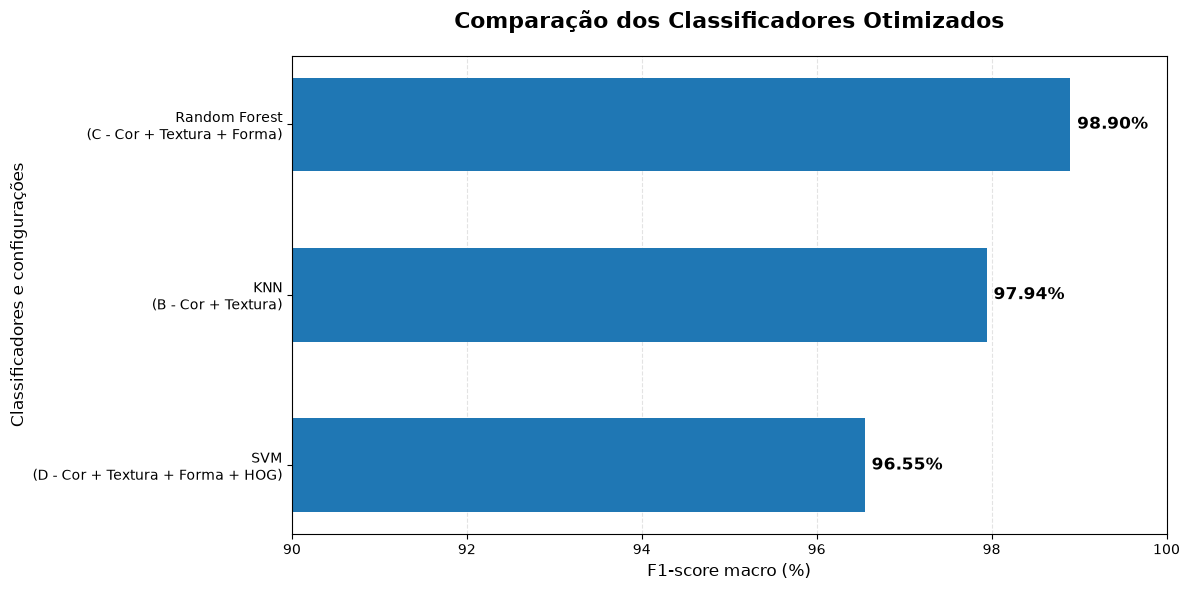

In [ ]:
#========================================================
# Organizar dos resultados comparação em gráfico
#========================================================
# Dados da comparação
nomes = [
    "Random Forest\n(C - Cor + Textura + Forma)",
    "KNN\n(B - Cor + Textura)",
    "SVM\n(D - Cor + Textura + Forma + HOG)"]

valores = [
    grid_rf_c.best_score_ * 100,
    grid_knn.best_score_ * 100,
    grid_svm.best_score_ * 100]

# Criar figura
fig, ax = plt.subplots(figsize=(12, 6))

# Barras horizontais
barras = ax.barh(nomes, valores, height=0.55)

# Inverter para deixar o maior resultado no topo
ax.invert_yaxis()

# Escala do eixo X
ax.set_xlim(90, 100)

# Títulos e rótulos
ax.set_title(
    "Comparação dos Classificadores Otimizados", fontsize=16, fontweight="bold", pad=20)

ax.set_xlabel( "F1-score macro (%)", fontsize=12)
ax.set_ylabel("Classificadores e configurações", fontsize=12)

# Adicionar percentual em cada barra
for barra, valor in zip(barras, valores):
    ax.text(
        valor + 0.08,
        barra.get_y() + barra.get_height() / 2,
        f"{valor:.2f}%",
        va="center",
        fontsize=12,
        fontweight="bold")

# Grade discreta
ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.35)

ax.set_axisbelow(True)

# Ajustes visuais
ax.tick_params(axis="both", labelsize=10)
plt.tight_layout()

#**********************************************
#   Salva o gráfico em uma resolução melhor
#********************************************** 
#plt.savefig(
#    "comparacao_classificadores.png",
#    dpi=300,
#    bbox_inches="tight")

plt.show()


## 5.10 Treinamento dos modelos finais

Agora vamos utilizar os melhores hiperparâmetros encontrados na otimização e treinar novamente cada classificador com os 37.528 exemplos originais de treinamento.

Depois, avaliaremos os modelos nas 12.528 imagens do conjunto de teste, que ainda não foram utilizadas na seleção dos hiperparâmetros.

In [ ]:
#=============================================
# Treinamento dos modelos finais  
#==============================================
# Recuperar os melhores hiperparâmetros
print("KNN:", grid_knn.best_params_)
print("SVM:", grid_svm.best_params_)
print("Random Forest:", grid_rf_c.best_params_)

KNN: {'knn__metric': 'manhattan', 'knn__n_neighbors': 3, 'knn__weights': 'distance'}
SVM: {'svm__C': 10, 'svm__gamma': 'scale'}
Random Forest: {'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 200}


In [ ]:
#====================================
#  Construir os modelos finais
#====================================
# KNN
modelo_knn_final = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(
        **{
            chave.replace("knn__", ""): valor
            for chave, valor in grid_knn.best_params_.items()
        }
    ))
])

# SVM
modelo_svm_final = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(
        kernel="rbf",
        **{
            chave.replace("svm__", ""): valor
            for chave, valor in grid_svm.best_params_.items()
        }
    ))
])

# Random Forest
modelo_rf_final = RandomForestClassifier(
    random_state=42,
    n_jobs=-1,
    **grid_rf_c.best_params_
)

In [ ]:
#================================================
# Treinando KNN - Configuração B
#================================================
inicio = time.time()

modelo_knn_final.fit(
    X_treino["B - Cor + Textura"],
    y_treino
)
print(f"Tempo KNN: {(time.time() - inicio)/60:.2f} minutos")


Tempo KNN: 0.01 minutos


In [ ]:
#================================================
# Treinando SVM - Configuração D
#================================================
inicio = time.time()

modelo_svm_final.fit(
    X_treino["D - Cor + Textura + Forma + HOG"],
    y_treino
)
print(f"Tempo SVM: {(time.time() - inicio)/60:.2f} minutos")


Tempo SVM: 5.81 minutos


In [ ]:
#================================================
#  Treinando Random Forest - Configuração C
#================================================
inicio = time.time() 

modelo_rf_final.fit(
    X_treino["C - Cor + Textura + Forma"],
    y_treino
)
print(f"Tempo Random Forest: {(time.time() - inicio)/60:.2f} minutos")

Tempo Random Forest: 7.15 minutos


## 5.11 Avaliação final dos classificadores

### 5.11.1 Avaliação das métricas gerais

In [ ]:
#===========================================
#  Avaliação final dos classificadores
#  Avaliação das métricas gerais
#===========================================

# Fazer previsões
y_pred_knn = modelo_knn_final.predict(
    X_teste["B - Cor + Textura"]
)

y_pred_svm = modelo_svm_final.predict(
    X_teste["D - Cor + Textura + Forma + HOG"]
)

y_pred_rf = modelo_rf_final.predict(
    X_teste["C - Cor + Textura + Forma"]
)

# Organizar previsões
previsoes = {
    "KNN": y_pred_knn,
    "SVM": y_pred_svm,
    "Random Forest": y_pred_rf
}

# Calcular métricas
resultados_teste = []

for nome, y_pred in previsoes.items():

    resultados_teste.append({
        "Classificador": nome,
        "Acurácia": accuracy_score(y_teste, y_pred),
        "Precisão macro": precision_score(
            y_teste, y_pred, average="macro", zero_division=0
        ),
        "Recall macro": recall_score(
            y_teste, y_pred, average="macro", zero_division=0
        ),
        "F1-score macro": f1_score(
            y_teste, y_pred, average="macro", zero_division=0
        )
    })

df_resultados_teste = pd.DataFrame(resultados_teste)

display(
    df_resultados_teste.round(4)
)
    

,Classificador,Acurácia,Precisão macro,Recall macro,F1-score macro
0,KNN,0.9844,0.9870,0.9846,0.9841
1,SVM,0.9725,0.9766,0.9708,0.9708
2,Random Forest,0.9867,0.9890,0.9863,0.9861


### 5.11.1.1 Análise dos Resultados

A avaliação final foi realizada utilizando o conjunto de teste, composto por 12.528 imagens, mantido separado durante o treinamento e a otimização dos hiperparâmetros.

O classificador Random Forest apresentou o melhor desempenho geral, alcançando acurácia de 98,67% e F1-score macro de 98,61%. O KNN também apresentou resultados expressivos, com F1-score macro de 98,41%, enquanto o SVM obteve 97,08%.

A diferença de apenas 0,20 ponto percentual entre Random Forest e KNN no F1-score macro demonstra que ambos apresentaram desempenho bastante próximo. De maneira geral, os três classificadores conseguiram distinguir as classes de frutas com elevado desempenho, com destaque para o Random Forest.



### 5.11.2 MÉTRICAS DE DESEMPENHO POR CLASSE

In [ ]:

# ============================================================
# MÉTRICAS DE DESEMPENHO POR CLASSE
# ============================================================

# Organizar as previsões dos classificadores
previsoes = {
    "KNN": y_pred_knn,
    "SVM": y_pred_svm,
    "Random Forest": y_pred_rf
}

# Identificar as classes presentes no conjunto de teste
classes = sorted(y_teste.unique())

# Armazenar os relatórios individuais
relatorios_por_classe = {}

for nome, y_pred in previsoes.items():

    # Gerar relatório de classificação
    relatorio = classification_report(
        y_teste,
        y_pred,
        labels=classes,
        output_dict=True,
        zero_division=0
    )

    # Transformar o relatório em DataFrame
    df_relatorio = pd.DataFrame(relatorio).T

    # Manter somente as métricas das classes
    df_relatorio = df_relatorio.loc[
        [str(classe) for classe in classes],
        ["precision", "recall", "f1-score", "support"]
    ]

    # Renomear as colunas
    df_relatorio.columns = [
        "Precisão",
        "Recall",
        "F1-score",
        "Suporte"
    ]

    # Armazenar resultado
    relatorios_por_classe[nome] = df_relatorio

    print(f"\n{'='*60}")
    print(f"MÉTRICAS POR CLASSE - {nome}")
    print(f"{'='*60}")

    display(df_relatorio.round(4))



MÉTRICAS POR CLASSE - KNN


,Precisão,Recall,F1-score,Suporte
Almonds 1,0.8261,1.0,0.9048,19.0
Apple 10,1.0000,1.0,1.0000,58.0
Apple 11,1.0000,1.0,1.0000,36.0
Apple 12,1.0000,1.0,1.0000,38.0
Apple 13,1.0000,1.0,1.0000,59.0
...,...,...,...,...
Zucchini Green 1,1.0000,1.0,1.0000,12.0
Zucchini dark 1,1.0000,1.0,1.0000,32.0
garlic bulb 1,1.0000,1.0,1.0000,40.0
grape pink 3,1.0000,1.0,1.0000,40.0



MÉTRICAS POR CLASSE - SVM


,Precisão,Recall,F1-score,Suporte
Almonds 1,1.0,1.0,1.0,19.0
Apple 10,1.0,1.0,1.0,58.0
Apple 11,1.0,1.0,1.0,36.0
Apple 12,1.0,1.0,1.0,38.0
Apple 13,1.0,1.0,1.0,59.0
...,...,...,...,...
Zucchini Green 1,1.0,1.0,1.0,12.0
Zucchini dark 1,1.0,1.0,1.0,32.0
garlic bulb 1,1.0,1.0,1.0,40.0
grape pink 3,1.0,1.0,1.0,40.0



MÉTRICAS POR CLASSE - Random Forest


,Precisão,Recall,F1-score,Suporte
Almonds 1,1.000,1.0,1.0000,19.0
Apple 10,1.000,1.0,1.0000,58.0
Apple 11,0.973,1.0,0.9863,36.0
Apple 12,1.000,1.0,1.0000,38.0
Apple 13,1.000,1.0,1.0000,59.0
...,...,...,...,...
Zucchini Green 1,1.000,1.0,1.0000,12.0
Zucchini dark 1,1.000,1.0,1.0000,32.0
garlic bulb 1,1.000,1.0,1.0000,40.0
grape pink 3,1.000,1.0,1.0000,40.0


In [58]:

# Salvar os relatórios individuais
for nome, df_relatorio in relatorios_por_classe.items():

    arquivo = (
        "metricas_por_classe_"
        + nome.lower().replace(" ", "_")
        + ".csv"
    )

    df_relatorio.to_csv(
        arquivo,
        encoding="utf-8-sig"
    )

    print(f"Arquivo salvo: {arquivo}")


Arquivo salvo: metricas_por_classe_knn.csv
Arquivo salvo: metricas_por_classe_svm.csv
Arquivo salvo: metricas_por_classe_random_forest.csv


### 5.11.3 Matrizes de confusão

Nosso objetivo agora é identificar:
- Quais classes de frutas foram classificadas corretamente.
- Quais classes apresentam maior quantidade de erros.
- Quais frutas são mais frequentemente confundidas entre si.
- Se o Random Forest mantém sua vantagem sobre KNN e SVM.

Serão três matrizes reduzidas:

- Matriz de confusão — KNN: cinco classes com mais erros do KNN.

- Matriz de confusão — SVM: cinco classes com mais erros do SVM.

- Matriz de confusão — Random Forest: cinco classes com mais erros do Random Forest.

In [59]:

# =====================================================
# MATRIZES DE CONFUSÃO REDUZIDAS — TOP 5 CLASSES COM ERROS
# =====================================================

def matriz_confusao_top5(y_real, y_pred, nome_modelo):

    # Converter para arrays
    y_real = np.asarray(y_real)
    y_pred = np.asarray(y_pred)

    # Obter todas as classes
    classes = sorted(np.unique(y_real))

    # Construir a matriz de confusão completa
    matriz = confusion_matrix(
        y_real,
        y_pred,
        labels=classes
    )

    # Calcular a quantidade de erros por classe
    erros = matriz.sum(axis=1) - matriz.diagonal()

    # Identificar as cinco classes com mais erros
    indices_top5 = np.argsort(erros)[::-1][:5]

    classes_top5 = [classes[i] for i in indices_top5]

    # Criar matriz reduzida
    matriz_reduzida = []

    for i in indices_top5:

        linha = []

        # Contagem das previsões para as cinco classes selecionadas
        for j in indices_top5:
            linha.append(matriz[i, j])

        # Agrupar previsões destinadas às demais classes
        outras = matriz[i].sum() - sum(linha)

        linha.append(outras)

        matriz_reduzida.append(linha)

    # Organizar em DataFrame
    colunas = classes_top5 + ["Outras classes"]

    df_matriz = pd.DataFrame(
        matriz_reduzida,
        index=classes_top5,
        columns=colunas
    )

    # Exibir matriz de confusão
    plt.figure(figsize=(11, 6))

    sns.heatmap(
        df_matriz,
        annot=True,
        fmt="d",
        cmap="Blues"
    )

    plt.title(
        f"Matriz de confusão reduzida — {nome_modelo}"
    )

    plt.xlabel("Classe predita")
    plt.ylabel("Classe real")

    plt.tight_layout()
    plt.show()

    return df_matriz



Matriz de confusão — KNN


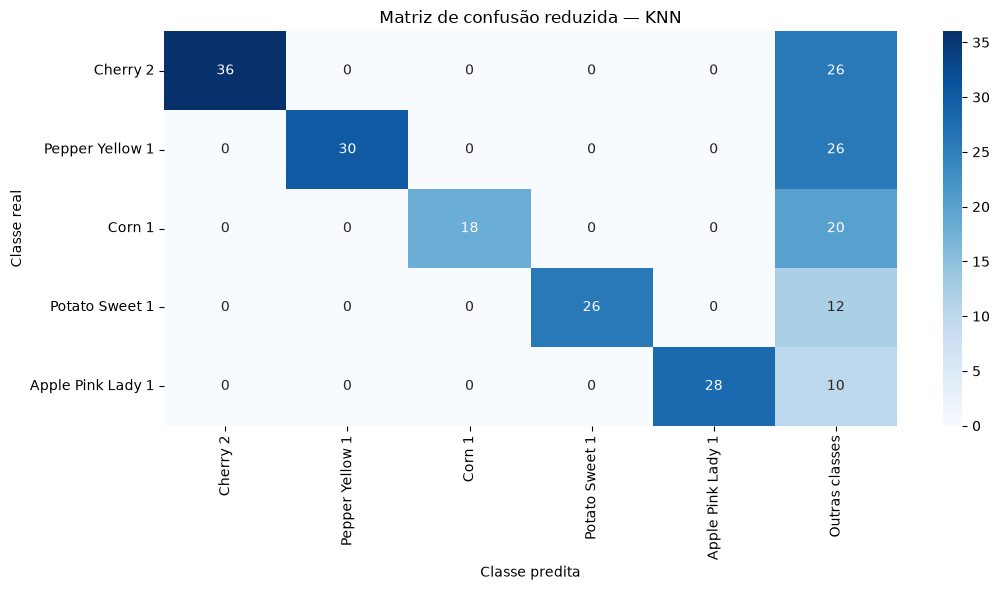

,Cherry 2,Pepper Yellow 1,Corn 1,Potato Sweet 1,Apple Pink Lady 1,Outras classes
Cherry 2,36,0,0,0,0,26
Pepper Yellow 1,0,30,0,0,0,26
Corn 1,0,0,18,0,0,20
Potato Sweet 1,0,0,0,26,0,12
Apple Pink Lady 1,0,0,0,0,28,10



Matriz de confusão — SVM


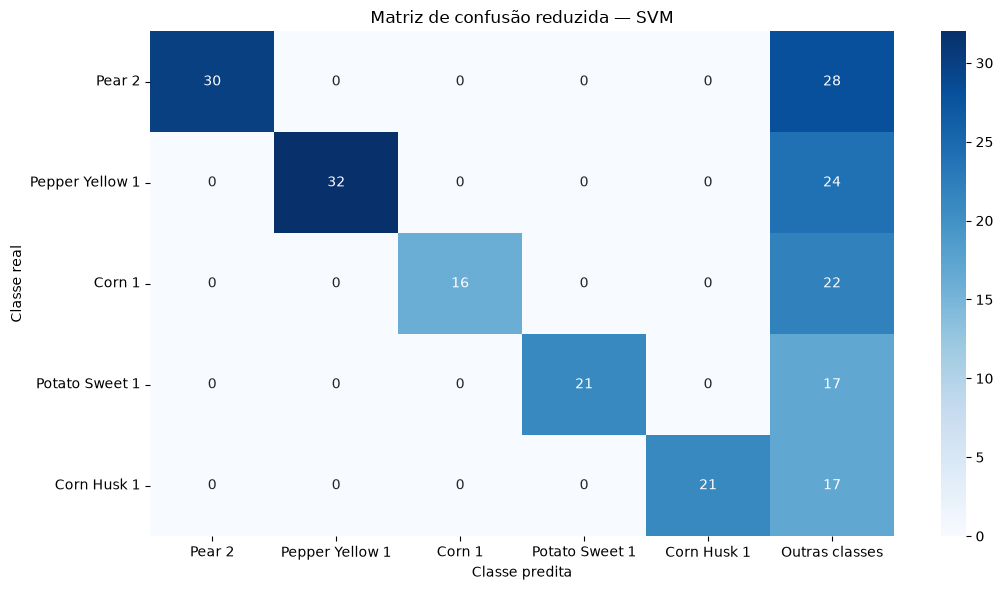

,Pear 2,Pepper Yellow 1,Corn 1,Potato Sweet 1,Corn Husk 1,Outras classes
Pear 2,30,0,0,0,0,28
Pepper Yellow 1,0,32,0,0,0,24
Corn 1,0,0,16,0,0,22
Potato Sweet 1,0,0,0,21,0,17
Corn Husk 1,0,0,0,0,21,17



Matriz de confusão — Random Forest


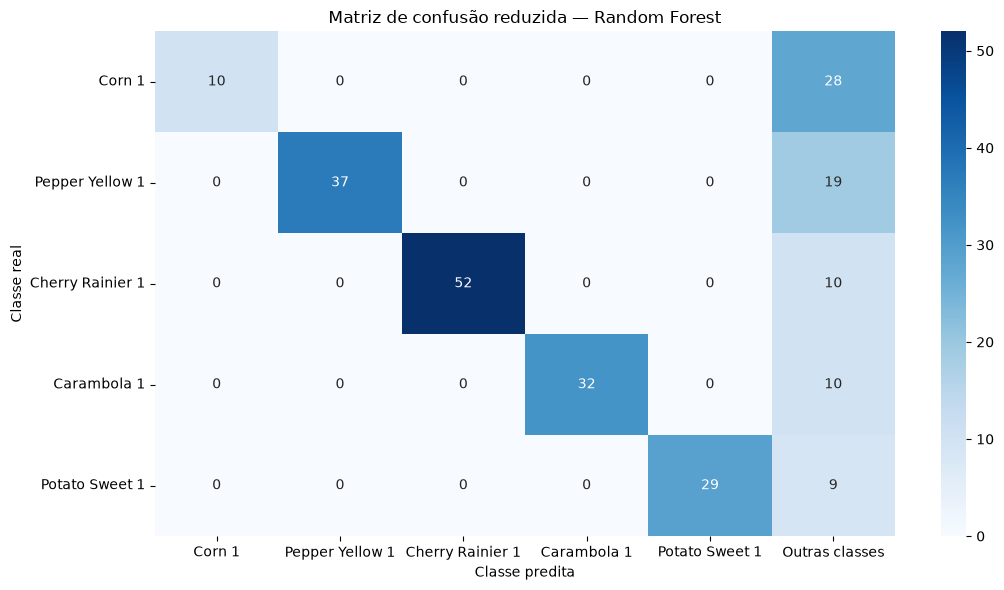

,Corn 1,Pepper Yellow 1,Cherry Rainier 1,Carambola 1,Potato Sweet 1,Outras classes
Corn 1,10,0,0,0,0,28
Pepper Yellow 1,0,37,0,0,0,19
Cherry Rainier 1,0,0,52,0,0,10
Carambola 1,0,0,0,32,0,10
Potato Sweet 1,0,0,0,0,29,9


In [60]:

# =====================================================
# EXECUÇÃO DAS MATRIZES DE CONFUSÃO REDUZIDAS
# =====================================================

matrizes_reduzidas = {}

for nome, y_pred in previsoes.items():

    print(f"\nMatriz de confusão — {nome}")

    df_matriz = matriz_confusao_top5(
        y_real=y_teste,
        y_pred=y_pred,
        nome_modelo=nome
    )

    matrizes_reduzidas[nome] = df_matriz

    display(df_matriz)


### 5.11.3.1 Análise das Matrizes

As matrizes de confusão reduzidas permitem identificar as classes que concentram a maior quantidade de erros em cada classificador. Observa-se que os três modelos apresentam dificuldades na classificação de determinadas variedades de frutas, com destaque para Pepper Yellow 1, que aparece entre as cinco classes com maior número de erros em todos os classificadores. O Random Forest apresentou menor quantidade de erros nessa classe em comparação ao KNN e ao SVM. Também foram observadas dificuldades em classes como Corn 1 e Potato Sweet 1, embora a intensidade dos erros varie entre os modelos. Esses resultados indicam que, apesar do elevado desempenho geral dos classificadores, algumas classes ainda apresentam desafios de identificação.

## 5.11.4 Comparação dos principais erros KNN, SVM e Random Forest
O objetivo é verificar se os três classificadores confundem as mesmas classes de frutas ou se cada um apresenta dificuldades diferentes.
Cada classificador será avaliado com a configuração de atributos que apresentou o melhor resultado na etapa de otimização.

In [44]:
#===========================================
#   Organizar os modelos
#==========================================

modelos_finais = {
    "KNN": {
        "modelo": modelo_knn_final,
        "X": X_teste["B - Cor + Textura"]
    },
    "SVM": {
        "modelo": modelo_svm_final,
        "X": X_teste["D - Cor + Textura + Forma + HOG"]
    },
    "Random Forest": {
        "modelo": modelo_rf_final,
        "X": X_teste["C - Cor + Textura + Forma"]
    }
}

In [45]:
#===================================================
#   Identificação dos principais erros
#===================================================

def analisar_confusoes(modelo, X, y_real, nome_modelo):

    # Realizar previsões
    y_pred = modelo.predict(X)

    # Obter as classes
    classes = sorted(y_real.unique())

    # Calcular matriz de confusão
    matriz = confusion_matrix(
        y_real,
        y_pred,
        labels=classes
    )

    # Remover a diagonal principal (acertos)
    matriz_erros = matriz.copy()
    np.fill_diagonal(matriz_erros, 0)

    # Identificar os pares de classes confundidas
    pares = []

    for i in range(len(classes)):
        for j in range(len(classes)):

            if matriz_erros[i, j] > 0:
                pares.append({
                    "Modelo": nome_modelo,
                    "Classe real": classes[i],
                    "Classe predita": classes[j],
                    "Quantidade": matriz_erros[i, j]
                })

    # Organizar do maior para o menor número de erros
    df_pares = pd.DataFrame(pares)

    return df_pares.sort_values(
        "Quantidade",
        ascending=False
    )

In [46]:
#=============================================
#   Execução da comparação
#============================================

resultados_confusoes = []

for nome, dados in modelos_finais.items():

    df_confusoes = analisar_confusoes(
        modelo=dados["modelo"],
        X=dados["X"],
        y_real=y_teste,
        nome_modelo=nome
    )

    resultados_confusoes.append(df_confusoes)

    print(f"\nPrincipais confusões — {nome}")
    display(df_confusoes.head(10))


Principais confusões — KNN


,Modelo,Classe real,Classe predita,Quantidade
41,KNN,Pepper Yellow 1,Pepper Orange 2,26
14,KNN,Cherry 2,Cherry 4,26
18,KNN,Corn 1,Physalis with Husk 1,18
4,KNN,Apple Pink Lady 1,Apple Red 2,10
45,KNN,Potato Sweet 1,Potato Red 1,9
3,KNN,Apple Golden 2,Apple Golden 3,6
33,KNN,Nectarine 1,Pomegranate 1,6
23,KNN,Eggplant 1,Pear Stone 1,6
0,KNN,Apple Crimson Snow 1,Apple Pink Lady 1,5
6,KNN,Apple Red 2,Apple Braeburn 1,5



Principais confusões — SVM


,Modelo,Classe real,Classe predita,Quantidade
90,SVM,Pepper Yellow 1,Pepper Orange 2,24
79,SVM,Pear Monster 1,Cactus fruit 1,15
33,SVM,Corn 1,Onion White 1,13
107,SVM,Tomato Heart 1,Pepper Red 1,12
23,SVM,Carambola 1,Cucumber 11,11
101,SVM,Potato Sweet 1,Potato White 1,10
15,SVM,Banana Lady Finger 1,Banana 3,9
81,SVM,Pepino 1,Apple 20,9
0,SVM,Apple Braeburn 1,Apple Red 2,9
70,SVM,Pear 2,Onion White 1,8



Principais confusões — Random Forest


,Modelo,Classe real,Classe predita,Quantidade
15,Random Forest,Corn 1,Physalis with Husk 1,22
35,Random Forest,Pepper Yellow 1,Pepper Orange 2,19
12,Random Forest,Cherry Rainier 1,Cherry Rainier 2,10
39,Random Forest,Potato Sweet 1,Potato Red 1,9
3,Random Forest,Apple Pink Lady 1,Apple Red 2,8
9,Random Forest,Carambola 1,Pear Monster 1,7
10,Random Forest,Cherry 2,Cherry 4,6
22,Random Forest,Eggplant 1,Pear Stone 1,5
33,Random Forest,Pepper Orange 1,Pepper Yellow 1,5
5,Random Forest,Apricot 1,Pepper Orange 2,5


### 5.11.4.1 Análise comparativa dos erros de classificação



A comparação dos principais erros permite identificar quais classes apresentam dificuldades semelhantes entre os classificadores e quais confusões são específicas de cada modelo.

Um dos resultados mais recorrentes foi a confusão entre *Pepper Yellow 1* e *Pepper Orange 2*. Essa classificação incorreta ocorreu 26 vezes no KNN, 24 vezes no SVM e 19 vezes no Random Forest. Esse resultado demonstra que essa distinção representa uma dificuldade comum aos três classificadores.

Outra confusão relevante ocorreu entre *Corn 1* e *Physalis with Husk 1*, com 18 ocorrências no KNN e 22 no Random Forest. Já o SVM apresentou 13 erros na classificação de *Corn 1* como *Onion White 1*, indicando um comportamento diferente dos demais modelos para essa classe.

Também foram observadas diferenças na classificação de variedades de cereja. O KNN apresentou 26 erros ao classificar *Cherry 2* como *Cherry 4*, enquanto o Random Forest apresentou seis ocorrências para esse mesmo par. Esse resultado indica que os classificadores podem apresentar dificuldades distintas mesmo quando avaliados sobre as mesmas imagens.

De maneira geral, a comparação demonstra que existem confusões compartilhadas entre os modelos, mas também erros específicos de cada classificador. Essas diferenças podem estar relacionadas à forma como cada algoritmo utiliza as características extraídas das imagens.

Embora o Random Forest tenha apresentado o melhor desempenho geral, com acurácia de 98,67% e F1-score macro de 98,61%, a análise dos erros mostra que seu desempenho não é superior em todas as situações. Portanto, a avaliação dos classificadores deve considerar tanto as métricas gerais quanto as dificuldades específicas de identificação de determinadas classes.